# MG-accelerated HMC with perturbative basis updates

Analysis of `Grid/examples/Example_mg_hmc.cc` runs: does a multigrid preconditioner whose near-null basis is kept current by first-order corrections pay back its setup cost inside HMC, compared with plain GCR on the same solves? Design: research hub, `projects/multigrid/notes/deflation-basis-hmc.md`.

**Current data.** SDCC runs on `ckpoint_lat.4000` ($16^3 \times 32$, 8 nodes), all with $\delta\tau = 0.025$, so every run follows the same trajectory 1 and the same per-step sources: step $s$ is the same field in every run.

| Job | Run | State |
|---|---|---|
| 425415 | Plain-GCR baseline, $\tau = 1$, $N_{\rm MD} = 40$, a force solve every 8th MD step | Complete, 3 trajectories |
| 425416 | MG, $k = 4$, coarse operator rebuilt only after an update | **Partial**: cancelled by Slurm at 15.3 h (`CANCELLED`, not by us), 8 MD steps and 1 finished update |
| 425417 | MG, $k = 16$, as 425416 | **Partial**: cancelled at 14.2 h, 7 MD steps, no update reached |
| 425418 | MG, $k = 40$ | Cancelled before it started |
| 425622 | MG, frozen basis ($k = 0$), coarse operator rebuilt every MD step, coarse GCR at 0.03 / 1000; $\tau = 0.4$, $N_{\rm MD} = 16$ | Complete, 16 MD steps |
| 425623 | As 425622 with a looser coarse solve, 0.1 / 200 | Complete, 16 MD steps |

The smoke runs ($4^4$ tepid, laptop) that this notebook was first built on are in `../logs/smoke_4444/`.

## 1. Definitions

### Algorithm

| Symbol | Code name | Definition |
|---|---|---|
| $A$ | — | $A = D_{\rm PV}^\dagger D_{\rm DW}(m)$, Möbius, $L_s = 16$, $m = 0.001$; the operator of every solve. |
| $U_0$, $U$ | — | Starting gauge field and current gauge field. |
| $U_\ell$ | — | Gauge field at the last basis update. |
| $N$ | — | Basis size, 40. |
| $V$ | — | The near-null basis as bred or as updated (never the block-orthonormalised copy inside the MG). |
| $S_0$ | — | The basis bred at $U_0$. |
| $Q$ | — | $1 - V(V^\dagger V)^{-1}V^\dagger$, projector onto the complement of $\mathrm{span}(V)$. |
| update | — | Every $k$ MD steps: $v \to (v - w)/\lVert v - w \rVert$ with $(QAQ)\,w = Q\,(A(U) - A(U_\ell))\,v$, solved by MG-preconditioned GCR to $\epsilon_C$; then the coarse operator is rebuilt. |
| $k$ | `update_every` | MD steps between updates (0 = never). |
| force solve | — | At every MD step, $A(U)\,x = \eta_s$ to $\epsilon_F$, standing in for the fermion force solve; $\eta_s$ is Gaussian, seeded by the global MD-step index, identical in every run. |
| $\epsilon_F$, $\epsilon_C$ | `eps_force`, `eps_corr` | Force and correction tolerances, $10^{-8}$ and $10^{-2}$. |
| coarse solve | — | Inside each MG application: GCR(10,10) on the coarse operator, unpreconditioned, to relative tolerance $\epsilon_{\rm c}$, capped at $n_{\rm c}$ steps. Coarse lattice $8^3 \times 16$ ($2^4$ blocks, all of $L_s$), 33-point stencil, $N \times N$ blocks. |
| $\epsilon_{\rm c}$, $n_{\rm c}$ | `coarse_tol`, `coarse_maxsteps` | $3 \times 10^{-2}$ and 1000 in jobs 425416–425418 (hard-coded then) and 425622; $0.1$ and 200 in 425623. |
| recoarsen | `recoarsen_every` | Rebuild the coarse operator $P^\dagger A(U) P$ from the unchanged basis before the force solve of every such MD step (0 = only after an update). Without it the coarse operator stays $P^\dagger A(U_\ell) P$ until the next update. |

### Cost categories

| Code name | Fine matvecs counted |
|---|---|
| `setup` | Breeding the basis (and any re-breed). |
| `coarsen` | Building the coarse operator: once at setup, after every update, and after a rejected trajectory restores the basis. |
| `force` | Force-solve stand-ins: the outer GCR plus the smoother inside the MG. |
| `correct` | The update's right-hand sides and correction solves. |
| `measure` | Diagnostics only (residual checks, invariance residuals, fresh-basis checks). **Excluded from the algorithm's cost.** |

A "fine matvec" is one application of $A$; the smoother's shifted operator counts the same. In jobs 425416–425418 coarse-operator applications are not counted, only timed; they are recovered here from the coarse GCR's own log lines (one step is one coarse matvec, plus one per restart for the true residual, which is ignored). From the next build on the driver counts them by category as well (`coarse_*` in `MGHMC-TRAJ` and `MGHMC-CUM`, three extra `MGHMC-STEP` columns (`coarse_matvecs`, `coarse_calls`, and `t_recoarsen`, the seconds spent rebuilding the coarse operator before the solve when `--recoarsen-every` is set), two extra `MGHMC-UPDATE` keys).

### Logged quantities

| Symbol | Code name | Definition |
|---|---|---|
| $d_U$ | `dU` | $1 - \langle \mathrm{Re}\,\mathrm{tr}(U_0^\dagger U)\rangle / 3$, gauge distance from the start (see `MG-Evolution.ipynb`). |
| $d_U^{(\ell)}$ | `dU_last` | The same distance measured from $U_\ell$. |
| iters | `iters` | Outer GCR steps of a solve. |
| relres | `relres` | $\lVert \eta - A x\rVert / \lVert \eta \rVert$ after the force solve. |
| $t_{\rm smooth}$, $t_{\rm coarse}$ | `t_smooth`, `t_coarse` | Wall time of one force solve spent in the smoother and in the coarse solve. |
| $r_{\rm before}$, $r_{\rm after}$ | `resid_before`, `resid_after` | Invariance residual $\big(\sum_b \lVert Q A v_b\rVert^2 / \sum_b \lVert v_b\rVert^2\big)^{1/2}$ with $A(U)$, before and after the update. |
| $c_{S_0}$ | `cap_S0` | Block-span capture of the updated basis by $\mathcal{B}(S_0)$: drift from the start. |
| $\mathrm{dist}^2$ | `dist2_prev` | Global-span $\sum_k \sin^2\theta_k$ between the basis before and after one update. |
| $\kappa_G$ | `gram_cond` | Condition number of $V^\dagger V$ after the update. |
| $\lVert w \rVert / \lVert v \rVert$ | `wratio` | Size of each correction. |
| $c_{\rm cur}$, $c_{S_0}^{\rm fresh}$ | `cap_cur`, `cap_S0_fresh` | Capture of a freshly bred basis at $U$ (the ground truth) by the current basis and by $S_0$. |
| $\rho$ | `rho` | Wall time of one coarse step over wall time of one fine matvec: the price of a coarse step in fine-matvec units. |

### Code variables

| Code name | Definition |
|---|---|
| `LOG_DIR` | Directory of the logs read here. |
| `MG_RUNS` | Map label → log file of each MG-path run. |
| `GCR_RUN` | Log file of the plain-GCR baseline. |
| `read_log(path)` | Parses one log's `MGHMC-` lines into tables `steps`, `updates`, `fresh`, `trajs`, `setup`, `cum`, and the run's `params`. |
| `read_coarse(path)` | Parses the coarse GCR's own log lines into table `coarse`: one row per segment of work (the force solve of an MD step, or an update), with the number of coarse solves, how many hit the cap, and their steps. |
| `md_time` | MD time of a step or update, $(\text{global step}) \times \delta\tau$ with $\delta\tau = \tau / N_{\rm MD}$ from the run's `MGHMC-PARAMS` line; the x-axis of every plot. |
| `dtau` | $\delta\tau$ of a run. |
| `runs` | Map label → parsed MG run; `gcr` the parsed baseline. |
| `t_fine` | Wall time of one fine matvec, from the baseline (pure GCR, so every second is a matvec plus its orthogonalisation). |
| `cost_curve(run)` | Cumulative algorithmic fine matvecs (setup + coarsen + force + correct) after each global MD step. |
| `time_curve(run)` | Cumulative algorithmic wall time (breeding + coarsening + force solves + updates) after each global MD step. |
| `gcr_curve(gcr, n, col)` | Cumulative baseline matvecs (`col="matvecs"`) or seconds (`col="seconds"`) over the same $n$ steps; if the baseline solved only every $m$-th step, each solve is taken to stand for $m$ steps. |
| `break_even` | First global MD step (multiplied by $\delta\tau$ for the printout) at which the MG path's cumulative cost drops below the baseline's (None if it never does within the run). |
| `pt`, `fmt` | The plotting library `plottools` and its styles, from `/Users/patrickoare/lqcd/utilities`. |
| `REF_COLOR`, `LEGEND` | Plot styling. |

In [1]:
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append('/Users/patrickoare/lqcd/utilities')
import plottools as pt
import formattools as fmt

LOG_DIR = Path("../logs/ckpoint_lat.4000")
MG_RUNS = {"k = 4": LOG_DIR / "MG_hmc_mg_k4_md40_425416.log",
           "k = 16": LOG_DIR / "MG_hmc_mg_k16_md40_425417.log",
           "frozen basis, recoarsened, 0.03/1000": LOG_DIR / "MG_hmc_mg_k0_md16_tau0.4_rc1_ct0.03_cs1000_425622.log",
           "frozen basis, recoarsened, 0.1/200": LOG_DIR / "MG_hmc_mg_k0_md16_tau0.4_rc1_ct0.1_cs200_425623.log"}
GCR_RUN = LOG_DIR / "MG_hmc_gcr_k4_md40_425415.log"

REF_COLOR = pt.pal[7]
LEGEND = dict(title_fontsize=fmt.default_style['fontsize'], fontsize=fmt.default_style['fontsize'],
              bbox_to_anchor=(1, 1), loc='upper left')

In [2]:
# The last three columns exist only in logs from builds that count coarse matvecs
STEP_COLS = ["traj", "step", "dU", "dU_last", "plaq", "iters", "matvecs", "seconds", "t_smooth", "t_coarse", "relres",
             "coarse_matvecs", "coarse_calls", "t_recoarsen"]

def _pairs(tokens):
    # "key value key value ..." -> dict of floats
    return {tokens[i]: float(tokens[i + 1]) for i in range(0, len(tokens) - 1, 2)}

def read_log(path):
    steps, updates, fresh, trajs, setup, cum, params = [], [], [], [], {}, {}, {}
    for line in open(path, errors="replace"):
        if "MGHMC-" not in line:
            continue
        body = line.split("MGHMC-", 1)[1].split()
        tag, tok = body[0], body[1:]
        if tag == "STEP":
            steps.append(dict(zip(STEP_COLS, map(float, tok))))
        elif tag == "UPDATE":
            i_it, i_w = tok.index("iters"), tok.index("wratio")
            row = {"traj": int(tok[0]), "step": int(tok[1])}
            row.update(_pairs(tok[2:i_it]))
            row["iters"] = [int(x) for x in tok[i_it + 1:i_w]]
            row["wratio"] = [float(x) for x in tok[i_w + 1:]]
            updates.append(row)
        elif tag == "FRESH":
            fresh.append({"traj": int(tok[0]), "step": int(tok[1]), "cap_cur": float(tok[2]), "cap_S0_fresh": float(tok[3])})
        elif tag == "TRAJ":
            row = {"traj": int(tok[0])}
            row.update(_pairs(tok[1:]))
            trajs.append(row)
        elif tag == "SETUP":
            setup = _pairs(tok)
        elif tag == "CUM":
            cum = _pairs(tok)
        elif tag == "PARAMS":
            params = {tok[i]: tok[i + 1] for i in range(0, len(tok) - 1, 2)}
    mdsteps = int(params["MDsteps"])
    dtau = float(params["trajL"]) / mdsteps
    steps = pd.DataFrame(steps)
    if len(steps):
        steps[["traj", "step", "iters", "matvecs"]] = steps[["traj", "step", "iters", "matvecs"]].astype(int)
        steps["global"] = (steps["traj"] - 1) * mdsteps + steps["step"]
        steps["md_time"] = steps["global"] * dtau
    updates = pd.DataFrame(updates)
    if len(updates):
        updates["global"] = (updates["traj"] - 1) * mdsteps + updates["step"]
        updates["md_time"] = updates["global"] * dtau
    return dict(steps=steps, updates=updates, fresh=pd.DataFrame(fresh),
                trajs=pd.DataFrame(trajs), setup=setup, cum=cum, params=params, dtau=dtau)

RE_CONV  = re.compile(r"Level 3 PGCR: Converged on iteration (\d+)")
RE_STEPS = re.compile(r"Level 3 PGCR\(\d+,\d+\) (\d+) steps")
SEGMENT_TAGS = ("SETUP", "STEP", "UPDATE")

def _summary(steps, capped):
    steps = np.array(steps, dtype=float)
    return dict(solves=len(steps), capped=capped, steps_total=steps.sum(),
                steps_mean=steps.mean() if len(steps) else np.nan,
                steps_max=steps.max() if len(steps) else np.nan)

def read_coarse(path, mdsteps):
    # Coarse solves are attributed to the MGHMC- line that FOLLOWS them: the
    # force solve of a step is logged after it, and so is an update. Work after
    # the last such line belongs to a segment still running when the log was copied.
    rows, steps, capped, last = [], [], 0, 0
    for line in open(path, errors="replace"):
        if "Level 3" in line:
            m = RE_CONV.search(line)
            if m:
                steps.append(int(m.group(1)))
                continue
            m = RE_STEPS.search(line)
            if m:
                last = int(m.group(1))
            elif "did not converge" in line:
                steps.append(last)
                capped += 1
            continue
        if "MGHMC-" in line:
            body = line.split("MGHMC-", 1)[1].split()
            if body[0] in SEGMENT_TAGS:
                kind = body[0].lower()
                traj, step = (int(body[1]), int(body[2])) if kind != "setup" else (1, 0)
                rows.append(dict(kind=kind, traj=traj, step=step, **_summary(steps, capped)))
                steps, capped = [], 0
    rows.append(dict(kind="running", traj=np.nan, step=np.nan, **_summary(steps, capped)))
    c = pd.DataFrame(rows)
    c["global"] = (c["traj"] - 1) * mdsteps + c["step"]
    return c

runs = {label: read_log(p) for label, p in MG_RUNS.items()}
for label, p in MG_RUNS.items():
    runs[label]["coarse"] = read_coarse(p, int(runs[label]["params"]["MDsteps"]))
gcr = read_log(GCR_RUN)
for label, r in runs.items():
    print(label, ":", len(r["steps"]), "steps,", len(r["updates"]), "updates,", len(r["trajs"]), "trajectories")
print("baseline :", len(gcr["steps"]), "solves,", len(gcr["trajs"]), "trajectories")

k = 4 : 8 steps, 1 updates, 0 trajectories
k = 16 : 7 steps, 0 updates, 0 trajectories
frozen basis, recoarsened, 0.03/1000 : 16 steps, 0 updates, 1 trajectories
frozen basis, recoarsened, 0.1/200 : 16 steps, 0 updates, 1 trajectories
baseline : 15 solves, 3 trajectories


## 2. The baseline

Plain GCR(16,16), unpreconditioned, capped at 20000 steps. The cap was hit by every solve of trajectories 1 and 2 except the last, so those solves stop at $\mathrm{relres} \sim 10^{-7}$, short of $\epsilon_F = 10^{-8}$: **the baseline's cost is a lower bound**. Trajectory 1 was rejected and restored, so trajectory 2 starts at $U_0$ again and repeats the same $d_U$; trajectory 3 starts from the accepted end of trajectory 2. The cap-free solves of trajectory 3 take about 15000–16000 steps.

In [3]:
s = gcr["steps"]
t_fine = (s["seconds"] / s["matvecs"]).median()
print(f"baseline: {s['matvecs'].mean():.0f} matvecs and {s['seconds'].mean():.0f} s per solve on average, "
      f"t_fine = {1e3 * t_fine:.1f} ms per matvec")
print(f"solves at the 20000-step cap: {(s['iters'] >= 20000).sum()} of {len(s)}")
display(gcr["trajs"])
s[["traj", "step", "md_time", "dU", "iters", "matvecs", "seconds", "relres"]]

baseline: 19492 matvecs and 320 s per solve on average, t_fine = 16.6 ms per matvec
solves at the 20000-step cap: 9 of 15


,traj,dH,accepted,restored,seconds,cum_force,cum_measure
0,1,1.315973,0.0,1.0,1744.40360,106250.0,5.0
1,2,0.852233,1.0,0.0,1727.82639,211010.0,10.0
2,3,0.901031,1.0,0.0,1339.73801,292382.0,15.0


,traj,step,md_time,dU,iters,matvecs,seconds,relres
0,1,8,0.2,0.051118,20000,21250,361.068328,8.771485e-08
1,1,16,0.4,0.181501,20000,21250,353.966156,5.026313e-08
2,1,24,0.6,0.340516,20000,21250,334.950999,1.697401e-07
3,1,32,0.8,0.483850,20000,21250,334.392113,4.878755e-07
4,1,40,1.0,0.592287,20000,21250,353.386561,2.027824e-07
5,2,8,1.2,0.051205,20000,21250,352.641622,9.205674e-08
6,2,16,1.4,0.181801,20000,21250,351.915909,1.386200e-07
7,2,24,1.6,0.340965,20000,21250,353.086553,3.205713e-08
8,2,32,1.8,0.484270,20000,21250,335.599333,1.444613e-08
9,2,40,2.0,0.592568,18596,19760,328.130716,9.998622e-09


## 3. Cost accounting

The MG path's cumulative cost after global MD step $s$ is setup + coarsening + force solves + corrections up to $s$. Coarsening is not logged per rebuild, but every rebuild costs the same number of matvecs as the one at setup (same $N$, same stencil), so each update, and each per-step recoarsening (`t_recoarsen` > 0), adds `setup["coarsen_matvecs"]`; its wall time is `t_recoarsen`. Fine matvecs leave out the coarse solves entirely, so the comparison is made twice: in fine matvecs, and in wall time, which includes them.

Cumulative fine matvecs, k = 4: MG 105735, baseline 21250 over the same 8 steps; break-even at MD time None
Cumulative fine matvecs, k = 16: MG 108373, baseline 18594 over the same 7 steps; break-even at MD time None
Cumulative fine matvecs, frozen basis, recoarsened, 0.03/1000: MG 297394, baseline 42500 over the same 16 steps; break-even at MD time None
Cumulative fine matvecs, frozen basis, recoarsened, 0.1/200: MG 304235, baseline 42500 over the same 16 steps; break-even at MD time None


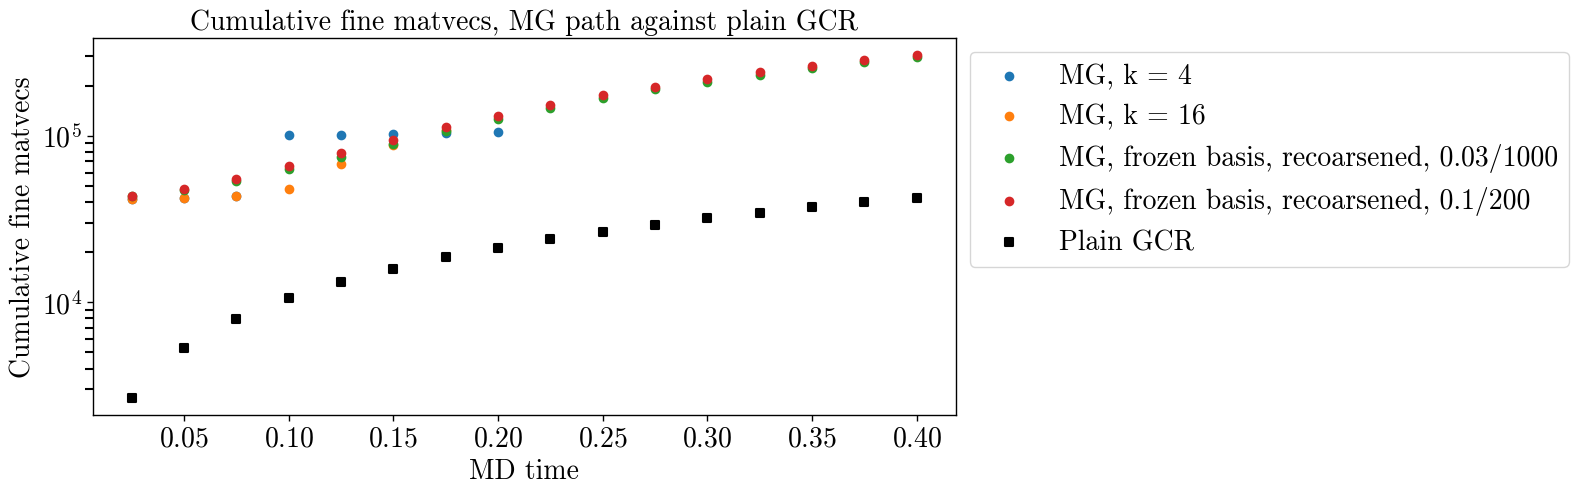

Cumulative wall time, k = 4: MG 47095, baseline 361 over the same 8 steps; break-even at MD time None
Cumulative wall time, k = 16: MG 50531, baseline 316 over the same 7 steps; break-even at MD time None
Cumulative wall time, frozen basis, recoarsened, 0.03/1000: MG 8259, baseline 715 over the same 16 steps; break-even at MD time None
Cumulative wall time, frozen basis, recoarsened, 0.1/200: MG 7476, baseline 715 over the same 16 steps; break-even at MD time None


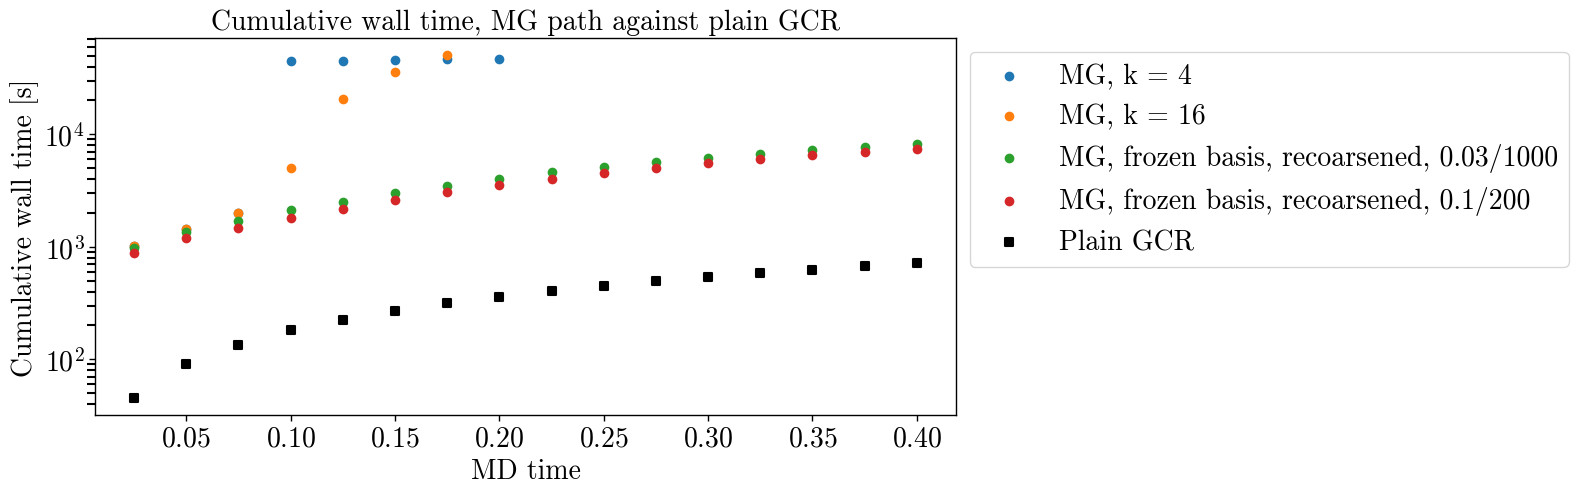

In [4]:
def cost_curve(run):
    s, u, setup = run["steps"], run["updates"], run["setup"]
    per_rebuild = setup["coarsen_matvecs"]
    per_step = s.set_index("global")["matvecs"].astype(float)
    if "t_recoarsen" in s:
        per_step += (s.set_index("global")["t_recoarsen"].fillna(0) > 0) * per_rebuild
    for g, mv in zip(u.get("global", []), u.get("matvecs", [])):
        per_step.loc[g] += mv + per_rebuild
    return setup["setup_matvecs"] + per_rebuild + per_step.cumsum()

def time_curve(run):
    s, u, setup = run["steps"], run["updates"], run["setup"]
    per_step = s.set_index("global")["seconds"].astype(float)
    if "t_recoarsen" in s:
        per_step += s.set_index("global")["t_recoarsen"].fillna(0)
    for g, sec, co in zip(u.get("global", []), u.get("seconds", []), u.get("coarsen_s", [])):
        per_step.loc[g] += sec + co
    return setup["breed_s"] + setup["coarsen_s"] + per_step.cumsum()

def gcr_curve(gcr, n, col="matvecs"):
    s = gcr["steps"]
    every = int(s["global"].diff().dropna().mode().iloc[0]) if len(s) > 1 else 1
    per_step = np.repeat(s[col].to_numpy() / every, every)[:n]
    return pd.Series(np.cumsum(per_step), index=np.arange(1, len(per_step) + 1))

def break_even(mg, base):
    common = mg.index.intersection(base.index)
    below = common[mg.loc[common].to_numpy() <= base.loc[common].to_numpy()]
    return int(below[0]) if len(below) else None

for curve, col, ylabel, title in [(cost_curve, "matvecs", r"Cumulative fine matvecs", "Cumulative fine matvecs"),
                                  (time_curve, "seconds", r"Cumulative wall time [s]", "Cumulative wall time")]:
    fig, ax = pt.add_subplots()
    ax = ax[0]
    labels = [r"MD time", ylabel]
    for i, (label, r) in enumerate(runs.items()):
        dtau = r["dtau"]
        mg = curve(r)
        pt.scatter_1d(mg.index * dtau, mg.to_numpy(), ax=ax, col=pt.pal[i], mkr='o', fn_label=f"MG, {label}", ax_label=labels, logy=True)
        base = gcr_curve(gcr, int(mg.index.max()), col)
        be = break_even(mg, base)
        print(f"{title}, {label}: MG {mg.iloc[-1]:.0f}, baseline {base.iloc[-1]:.0f} over the same "
              f"{int(mg.index.max())} steps; break-even at MD time {None if be is None else be * dtau}")
    pt.scatter_1d(base.index * dtau, base.to_numpy(), ax=ax, col='k', mkr='s', fn_label="Plain GCR", ax_label=labels, logy=True)
    pt.add_title(ax, f"{title}, MG path against plain GCR")
    ax.legend(**LEGEND)
    plt.show()

## 4. Comparison along trajectory 1

Every run below follows the same field at the same MD time, so the curves differ only in the solver. The baseline's points are its trajectory-1 solves at MD time 0.2 and 0.4 (steps 8 and 16); its iterations are unpreconditioned GCR steps and are capped at 20000. The dashed line is the MG outer cap of 1008 steps, at which a solve stops short of $\epsilon_F$. The $k = 4$ and $k = 16$ runs are identical up to step 4 (MD time 0.1), so their first four points overlap; $k = 4$ then updates its basis, and $k = 16$ carries on with the step-0 basis and coarse operator.

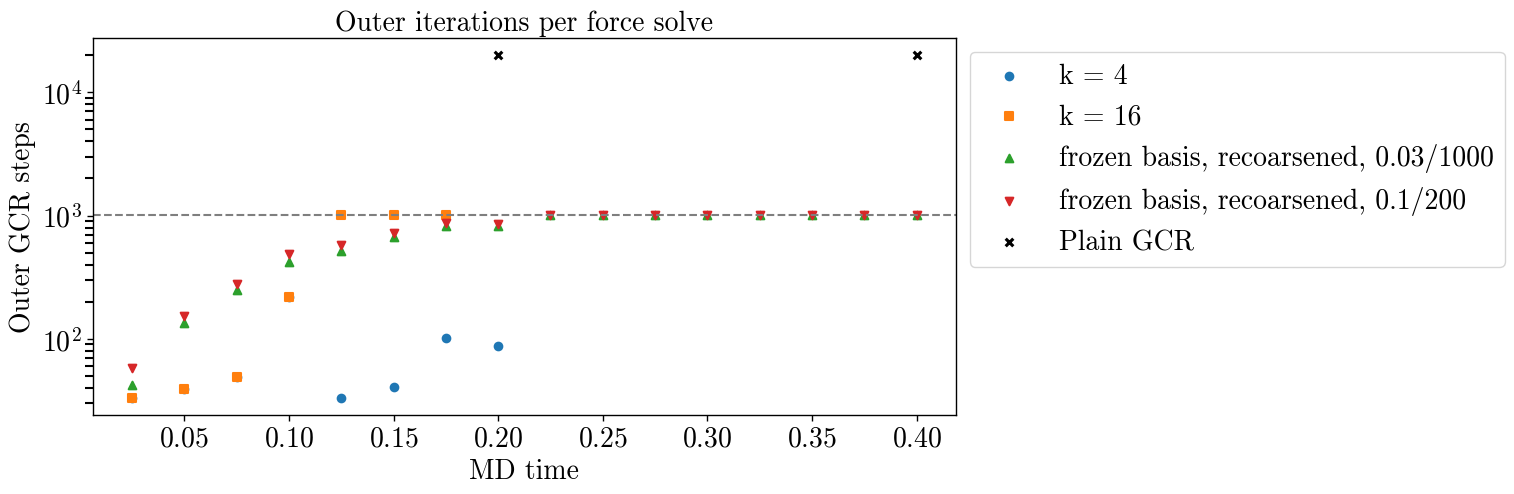

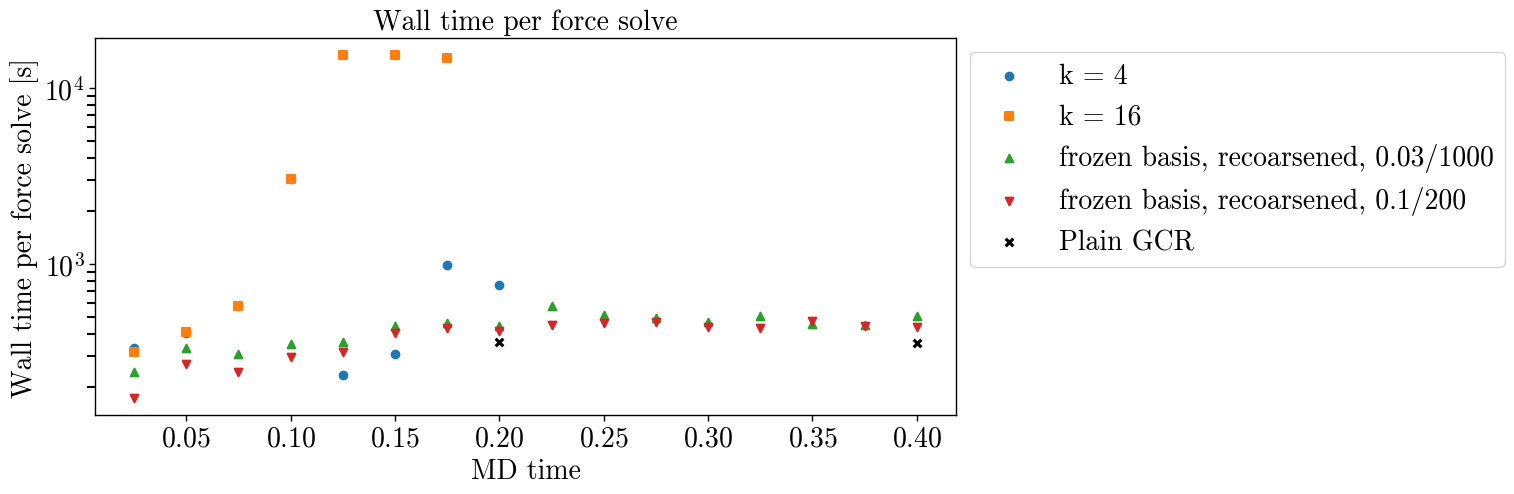

iters                                               \
      k = 4  k = 16 frozen basis, recoarsened, 0.03/1000   
step                                                       
1      33.0    33.0                                   42   
2      39.0    39.0                                  135   
3      49.0    49.0                                  247   
4     217.0   217.0                                  421   
5      33.0  1008.0                                  515   
6      41.0  1008.0                                  665   
7     101.0  1008.0                                  826   
8      88.0     NaN                                  821   
9       NaN     NaN                                 1008   
10      NaN     NaN                                 1008   
11      NaN     NaN                                 1008   
12      NaN     NaN                                 1008   
13      NaN     NaN                                 1008   
14      NaN     NaN                                 1008   
15      NaN     NaN                                 1008   
16      NaN     NaN                                 1008   

                                             seconds                \
     frozen basis, recoarsened, 0.1/200        k = 4        k = 16   
step                                                                 
1                                    58   332.467902    317.755171   
2                                   153   405.019521    409.084594   
3                                   281   576.337880    579.084219   
4                                   484  3032.393970   3047.977500   
5                                   579   233.186952  15369.454200   
6                                   727   307.000890  15346.335700   
7                                   874   982.272716  14760.681300   
8                                   857   760.295385           NaN   
9                                  1008          NaN           NaN   
10                                 1008          NaN           NaN   
11                                 1008          NaN           NaN   
12                                 1008          NaN           NaN   
13                                 1008          NaN           NaN   
14                                 1008          NaN           NaN   
15                                 1008          NaN           NaN   
16                                 1008          NaN           NaN   

                                                                              \
     frozen basis, recoarsened, 0.03/1000 frozen basis, recoarsened, 0.1/200   
step                                                                           
1                              245.163604                         172.874775   
2                              331.280799                         272.135860   
3                              309.255798                         242.513328   
4                              352.634330                         298.153386   
5                              359.123643                         316.766901   
6                              446.309311                         404.169932   
7                              465.021081                         431.468915   
8                              443.590685                         413.861121   
9                              577.754930                         451.083162   
10                             510.092473                         464.134117   
11                             493.563327                         465.711994   
12                             470.398878                         441.360577   
13                             508.395127                         430.514518   
14                             459.118461                         476.812308   
15                             449.844500                         445.604405   
16                             504.189227                         441.206780   

            r

In [5]:
gcr1 = gcr["steps"][(gcr["steps"]["traj"] == 1) & (gcr["steps"]["md_time"] <= 0.41)]
markers = ['o', 's', '^', 'v', 'D']
for col, ylabel, title, cap in [("iters", r"Outer GCR steps", "Outer iterations per force solve", 1008),
                                ("seconds", r"Wall time per force solve [s]", "Wall time per force solve", None)]:
    fig, ax = pt.add_subplots()
    ax = ax[0]
    labels = [r"MD time", ylabel]
    for i, (label, r) in enumerate(runs.items()):
        s = r["steps"]
        s = s[s["traj"] == 1]
        pt.scatter_1d(s["md_time"], s[col], ax=ax, col=pt.pal[i], mkr=markers[i], fn_label=label, ax_label=labels, logy=True)
    pt.scatter_1d(gcr1["md_time"], gcr1[col], ax=ax, col='k', mkr='x', fn_label="Plain GCR", ax_label=labels, logy=True)
    if cap is not None:
        ax.axhline(cap, color=REF_COLOR, ls='--')
    pt.add_title(ax, title)
    ax.legend(**LEGEND)
    plt.show()

pd.concat({label: r["steps"][["step", "md_time", "dU", "iters", "matvecs", "seconds", "t_coarse", "relres"]].set_index("step")
           for label, r in runs.items()}, axis=1).swaplevel(axis=1)[["iters", "seconds", "relres"]]

## 5. Force solves along the trajectory

Outer iterations are low and the fine matvecs per solve are 5–30× below the baseline, but nearly all of the wall time is in the coarse solve.

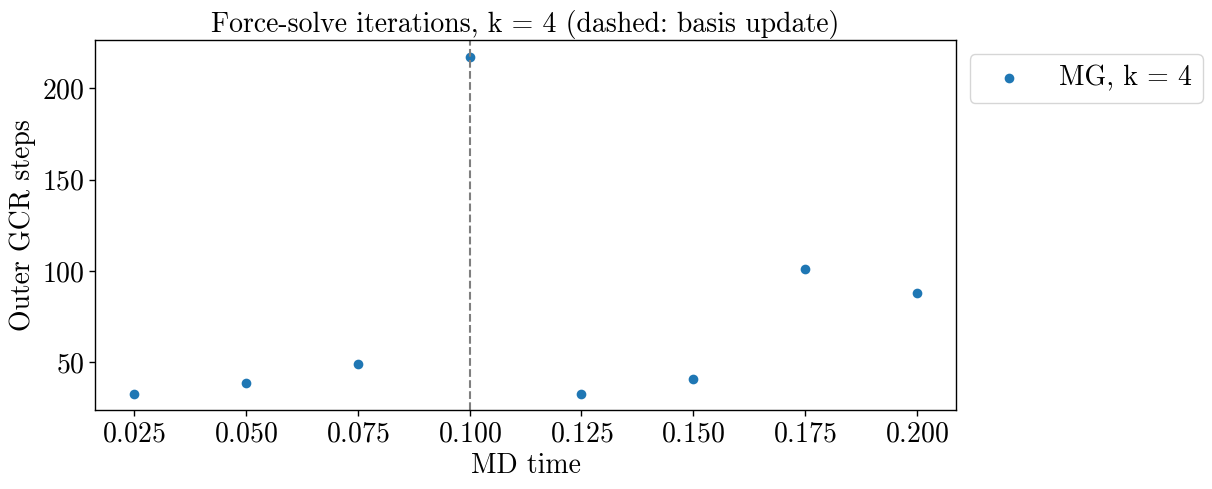

,global,md_time,dU,dU_last,iters,matvecs,seconds,t_smooth,t_coarse,coarse_frac,vs_gcr_matvecs,vs_gcr_seconds,relres
0,1,0.025,0.000832,0.000832,33,652,332.467902,9.080620,321.265810,0.966306,29.895910,0.961043,8.514128e-09
1,2,0.050,0.003322,0.003322,39,772,405.019521,10.743251,391.801217,0.967364,25.248877,0.788890,9.575445e-09
2,3,0.075,0.007451,0.007451,49,973,576.337880,12.971293,560.170830,0.971949,20.033025,0.554390,9.407114e-09
3,4,0.100,0.013184,0.013184,217,4343,3032.393970,61.692440,2957.052440,0.975154,4.488173,0.105368,9.845872e-09
4,5,0.125,0.020479,0.000832,33,652,233.186952,8.421966,222.548181,0.954377,29.895910,1.370213,8.874316e-09
5,6,0.150,0.029279,0.003323,41,812,307.000890,12.383775,291.918896,0.950873,24.005090,1.040765,9.963650e-09
6,7,0.175,0.039518,0.007451,101,2016,982.272716,27.528466,948.366250,0.965482,9.668717,0.325282,9.994072e-09
7,8,0.200,0.051118,0.013187,88,1755,760.295385,22.943072,732.022208,0.962813,11.106629,0.420252,9.548710e-09


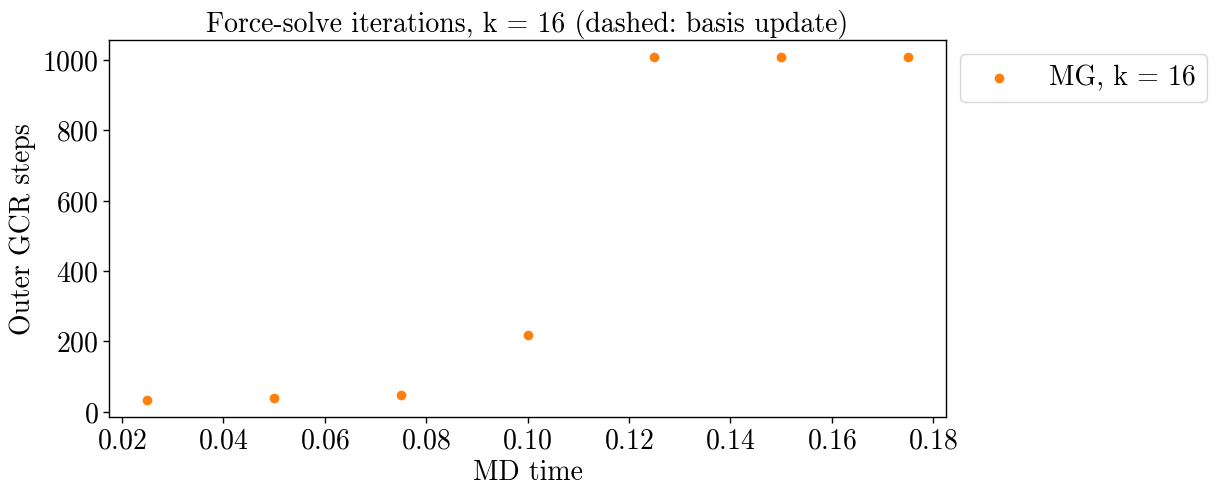

,global,md_time,dU,dU_last,iters,matvecs,seconds,t_smooth,t_coarse,coarse_frac,vs_gcr_matvecs,vs_gcr_seconds,relres
0,1,0.025,0.000832,0.000832,33,652,317.755171,8.928658,306.666625,0.965103,29.895910,1.005541,8.514128e-09
1,2,0.050,0.003322,0.003322,39,772,409.084594,10.682667,395.867839,0.967692,25.248877,0.781051,9.575445e-09
2,3,0.075,0.007451,0.007451,49,973,579.084219,15.727928,559.882620,0.966841,20.033025,0.551761,9.407114e-09
3,4,0.100,0.013184,0.013184,217,4343,3047.977500,57.406402,2977.589210,0.976907,4.488173,0.104829,9.845872e-09
4,5,0.125,0.020479,0.020479,1008,20211,15369.454200,285.557118,15019.338600,0.977220,0.964432,0.020789,5.057201e-06
5,6,0.150,0.029279,0.029279,1008,20211,15346.335700,286.056536,14994.794100,0.977093,0.964432,0.020820,3.408947e-03
6,7,0.175,0.039518,0.039518,1008,20211,14760.681300,287.275501,14408.337900,0.976130,0.964432,0.021646,3.010726e-03


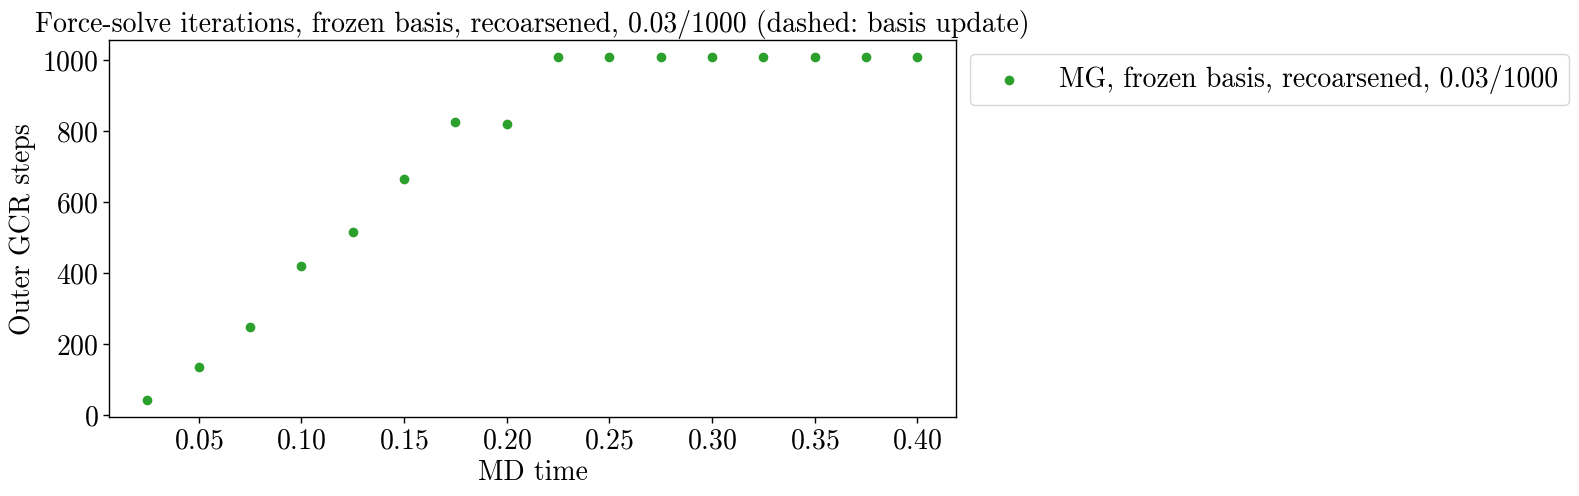

,global,md_time,dU,dU_last,iters,matvecs,seconds,t_smooth,t_coarse,coarse_frac,vs_gcr_matvecs,vs_gcr_seconds,relres
0,1,0.025,0.000832,0.000832,42,832,245.163604,11.136560,231.206410,0.943070,23.428045,1.303276,8.739660e-09
1,2,0.050,0.003322,0.003322,135,2698,331.280799,38.803420,284.094408,0.857564,7.224660,0.964487,9.739714e-09
2,3,0.075,0.007451,0.007451,247,4945,309.255798,65.152443,228.902023,0.740171,3.941786,1.033177,9.731252e-09
3,4,0.100,0.013184,0.013184,421,8436,352.634330,114.013820,212.612087,0.602925,2.310590,0.906083,9.871878e-09
4,5,0.125,0.020479,0.020479,515,10322,359.123643,141.469377,185.360543,0.516147,1.888407,0.889710,9.970302e-09
5,6,0.150,0.029279,0.029279,665,13331,446.309311,198.751262,202.301323,0.453276,1.462166,0.715907,9.862700e-09
6,7,0.175,0.039518,0.039518,826,16561,465.021081,221.786923,192.182461,0.413277,1.176990,0.687100,9.994000e-09
7,8,0.200,0.051118,0.051118,821,16461,443.590685,218.584031,173.120946,0.390272,1.184140,0.720294,9.985490e-09
8,9,0.225,0.063995,0.063995,1008,20211,577.754930,296.716040,213.509138,0.369550,0.964432,0.553030,1.089465e-08
9,10,0.250,0.078057,0.078057,1008,20211,510.092473,284.304764,160.426843,0.314505,0.964432,0.626388,2.105125e-08


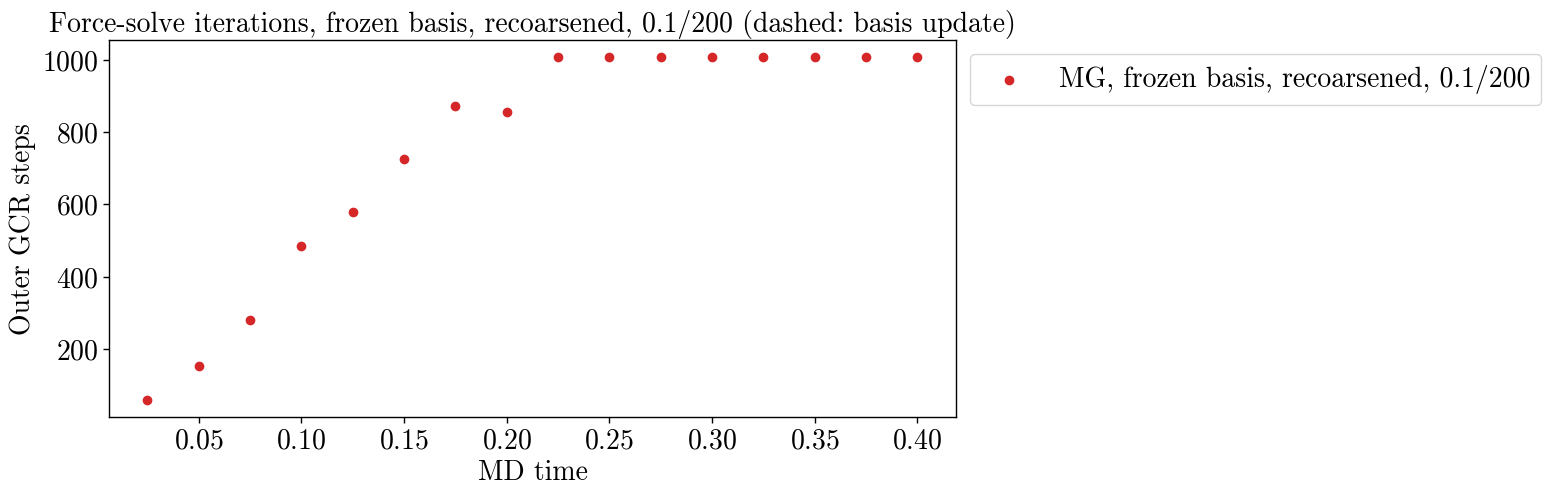

,global,md_time,dU,dU_last,iters,matvecs,seconds,t_smooth,t_coarse,coarse_frac,vs_gcr_matvecs,vs_gcr_seconds,relres
0,1,0.025,0.000832,0.000832,58,1153,172.874775,15.167599,154.098924,0.891390,16.905580,1.848251,9.781331e-09
1,2,0.050,0.003322,0.003322,153,3059,272.135860,48.018123,214.097629,0.786731,6.372061,1.174104,9.448378e-09
2,3,0.075,0.007451,0.007451,281,5627,242.513328,75.471225,149.911715,0.618159,3.464036,1.317519,9.690105e-09
3,4,0.100,0.013184,0.013184,484,9700,298.153386,130.026860,138.199506,0.463518,2.009498,1.071649,9.985161e-09
4,5,0.125,0.020479,0.020479,579,11606,316.766901,153.752655,125.827695,0.397225,1.679488,1.008678,9.965410e-09
5,6,0.150,0.029279,0.029279,727,14575,404.169932,216.545181,139.558067,0.345296,1.337368,0.790548,9.965221e-09
6,7,0.175,0.039518,0.039518,874,17524,431.468915,245.513872,131.925910,0.305760,1.112311,0.740531,9.890194e-09
7,8,0.200,0.051118,0.051118,857,17183,413.861121,243.836581,116.999162,0.282702,1.134385,0.772037,9.967950e-09
8,9,0.225,0.063995,0.063995,1008,20211,451.083162,269.957509,120.131793,0.266319,0.964432,0.708330,1.580279e-08
9,10,0.250,0.078057,0.078057,1008,20211,464.134117,280.671799,120.245522,0.259075,0.964432,0.688413,2.769791e-08


In [6]:
for i, (label, r) in enumerate(runs.items()):
    s = r["steps"].copy()
    s["coarse_frac"] = s["t_coarse"] / s["seconds"]
    s["vs_gcr_matvecs"] = gcr["steps"]["matvecs"].mean() / s["matvecs"]
    s["vs_gcr_seconds"] = gcr["steps"]["seconds"].mean() / s["seconds"]

    fig, ax = pt.add_subplots()
    ax = ax[0]
    pt.scatter_1d(s["md_time"], s["iters"], ax=ax, col=pt.pal[i], mkr='o', fn_label=f"MG, {label}",
                  ax_label=[r"MD time", r"Outer GCR steps"])
    for t in r["updates"].get("md_time", []):
        ax.axvline(t, color=REF_COLOR, ls='--')
    pt.add_title(ax, f"Force-solve iterations, {label} (dashed: basis update)")
    ax.legend(**LEGEND)
    plt.show()
    display(s[["global", "md_time", "dU", "dU_last", "iters", "matvecs", "seconds", "t_smooth", "t_coarse",
               "coarse_frac", "vs_gcr_matvecs", "vs_gcr_seconds", "relres"]])

## 6. The coarse solves

Each MG application makes one coarse solve. `solves` is the number in a segment, `capped` how many stopped at $n_{\rm c}$ without reaching $\epsilon_{\rm c}$, and `steps_*` their GCR steps. $\rho$ prices a coarse step in fine matvecs: it is $t_{\rm coarse}$ divided by the coarse steps of that force solve, over $t_{\rm fine}$ from the baseline. The cost of a force solve in fine-matvec equivalents is then $\text{matvecs} + \rho \times \text{coarse steps}$.

,kind,traj,step,solves,capped,steps_total,steps_mean,steps_max,global
0,setup,1.0,0.0,0,0,0.0,NaN,NaN,0.0
1,step,1.0,1.0,33,0,21113.0,639.787879,916.0,1.0
2,step,1.0,2.0,39,1,26025.0,667.307692,1000.0,2.0
3,step,1.0,3.0,49,9,36971.0,754.510204,1000.0,3.0
4,step,1.0,4.0,217,118,196725.0,906.566820,1000.0,4.0
5,update,1.0,4.0,2560,2556,2559904.0,999.962500,1000.0,4.0
6,step,1.0,5.0,33,0,15426.0,467.454545,641.0,5.0
7,step,1.0,6.0,41,0,19672.0,479.804878,719.0,6.0
8,step,1.0,7.0,101,0,63886.0,632.534653,883.0,7.0
9,step,1.0,8.0,88,0,52187.0,593.034091,847.0,8.0


k = 4: rho median 0.90; force solve in fine-matvec equivalents, mean 49862 against the baseline's 19492


,global,md_time,solves,capped,steps_mean,steps_total,rho,matvecs,equiv_matvecs
0,1.0,0.025,33,0,639.787879,21113.0,0.916336,652,19998.596024
1,2.0,0.050,39,1,667.307692,26025.0,0.906599,772,24366.231416
2,3.0,0.075,49,9,754.510204,36971.0,0.912430,973,34706.433236
3,4.0,0.100,217,118,906.566820,196725.0,0.905190,4343,182416.412104
4,5.0,0.125,33,0,467.454545,15426.0,0.868782,652,14053.829948
5,6.0,0.150,41,0,479.804878,19672.0,0.893622,812,18391.327700
6,7.0,0.175,101,0,632.534653,63886.0,0.893944,2016,59126.523905
7,8.0,0.200,88,0,593.034091,52187.0,0.844699,1755,45837.306608


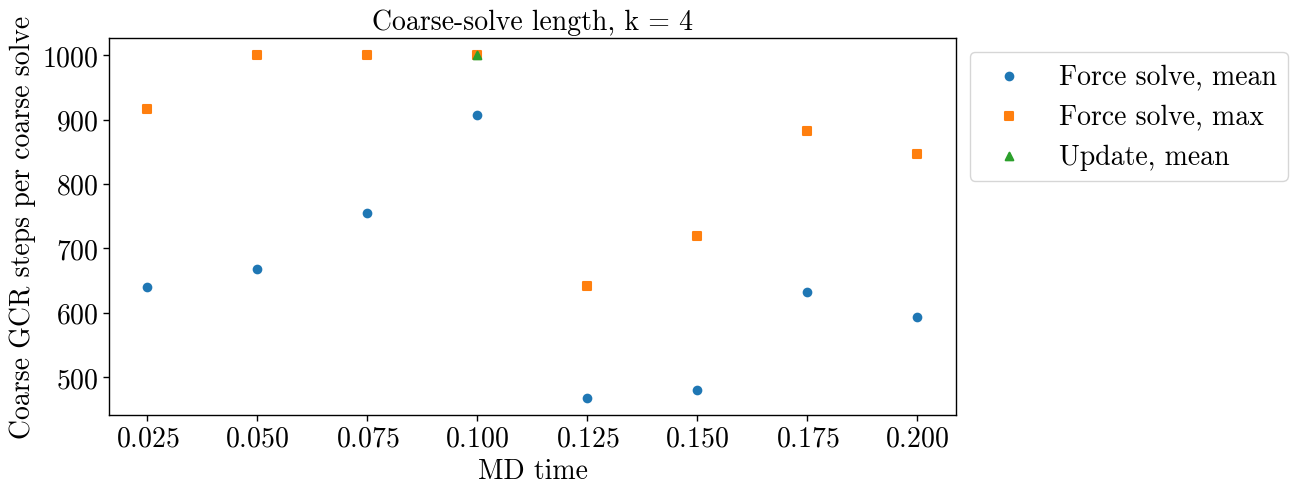

,kind,traj,step,solves,capped,steps_total,steps_mean,steps_max,global
0,setup,1.0,0.0,0,0,0.0,NaN,NaN,0.0
1,step,1.0,1.0,33,0,21113.0,639.787879,916.0,1.0
2,step,1.0,2.0,39,1,26025.0,667.307692,1000.0,2.0
3,step,1.0,3.0,49,9,36971.0,754.510204,1000.0,3.0
4,step,1.0,4.0,217,118,196725.0,906.566820,1000.0,4.0
5,step,1.0,5.0,1008,948,991940.0,984.067460,1000.0,5.0
6,step,1.0,6.0,1008,989,1000925.0,992.981151,1000.0,6.0
7,step,1.0,7.0,1008,980,1001453.0,993.504960,1000.0,7.0
8,running,NaN,NaN,34,5,27684.0,814.235294,1000.0,NaN


k = 16: rho median 0.91; force solve in fine-matvec equivalents, mean 428260 against the baseline's 19492


,global,md_time,solves,capped,steps_mean,steps_total,rho,matvecs,equiv_matvecs
0,1.0,0.025,33,0,639.787879,21113.0,0.874695,652,19119.434515
1,2.0,0.050,39,1,667.307692,26025.0,0.916009,772,24611.123000
2,3.0,0.075,49,9,754.510204,36971.0,0.911960,973,34689.077257
3,4.0,0.100,217,118,906.566820,196725.0,0.911476,4343,183653.134409
4,5.0,0.125,1008,948,984.067460,991940.0,0.911812,20211,924674.118704
5,6.0,0.150,1008,989,992.981151,1000925.0,0.902151,20211,923196.051287
6,7.0,0.175,1008,980,993.504960,1001453.0,0.866410,20211,887879.715610


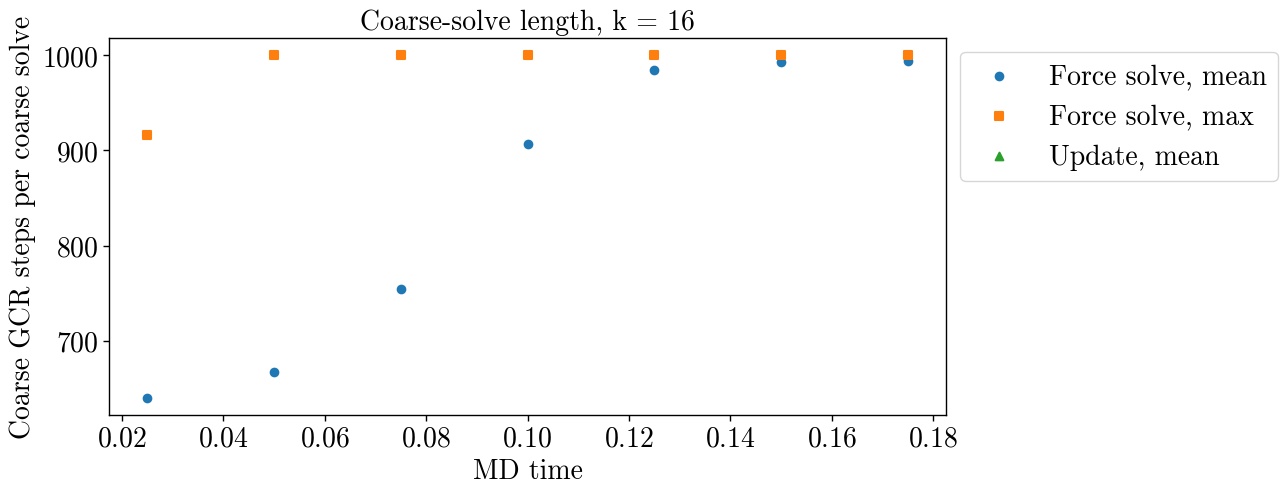

,kind,traj,step,solves,capped,steps_total,steps_mean,steps_max,global
0,setup,1.0,0.0,0,0,0.0,NaN,NaN,0.0
1,step,1.0,1.0,42,0,15310.0,364.523810,440.0,1.0
2,step,1.0,2.0,135,0,20004.0,148.177778,157.0,2.0
3,step,1.0,3.0,247,0,16371.0,66.279352,74.0,3.0
4,step,1.0,4.0,421,0,15180.0,36.057007,45.0,4.0
5,step,1.0,5.0,515,0,12926.0,25.099029,32.0,5.0
6,step,1.0,6.0,665,0,12399.0,18.645113,24.0,6.0
7,step,1.0,7.0,826,0,12826.0,15.527845,19.0,7.0
8,step,1.0,8.0,821,0,11316.0,13.783191,17.0,8.0
9,step,1.0,9.0,1008,0,12117.0,12.020833,15.0,9.0


frozen basis, recoarsened, 0.03/1000: rho median 0.94; force solve in fine-matvec equivalents, mean 25541 against the baseline's 19492


,global,md_time,solves,capped,steps_mean,steps_total,rho,matvecs,equiv_matvecs
0,1.0,0.025,42,0,364.523810,15310.0,0.909420,832,14755.227662
1,2.0,0.050,135,0,148.177778,20004.0,0.855236,2698,19806.137789
2,3.0,0.075,247,0,66.279352,16371.0,0.842005,4945,18729.457699
3,4.0,0.100,421,0,36.057007,15180.0,0.843444,8436,21239.479328
4,5.0,0.125,515,0,25.099029,12926.0,0.863561,10322,21484.393982
5,6.0,0.150,665,0,18.645113,12399.0,0.982544,13331,25513.566116
6,7.0,0.175,826,0,15.527845,12826.0,0.902324,16561,28134.209225
7,8.0,0.200,821,0,13.783191,11316.0,0.921291,16461,26886.326634
8,9.0,0.225,1008,0,12.020833,12117.0,1.061112,20211,33068.499652
9,10.0,0.250,1008,0,10.060516,10141.0,0.952656,20211,29871.888978


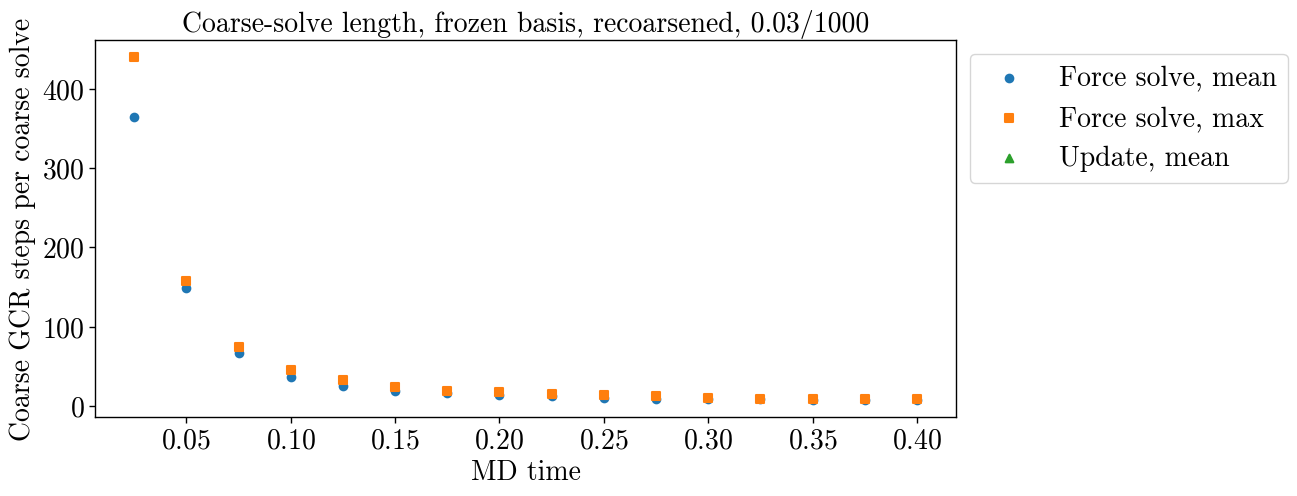

,kind,traj,step,solves,capped,steps_total,steps_mean,steps_max,global
0,setup,1.0,0.0,0,0,0.0,NaN,NaN,0.0
1,step,1.0,1.0,58,51,10651.0,183.637931,200.0,1.0
2,step,1.0,2.0,153,0,14560.0,95.163399,101.0,2.0
3,step,1.0,3.0,281,0,10876.0,38.704626,47.0,3.0
4,step,1.0,4.0,484,0,9535.0,19.700413,29.0,4.0
5,step,1.0,5.0,579,0,8332.0,14.390328,20.0,5.0
6,step,1.0,6.0,727,0,8398.0,11.551582,16.0,6.0
7,step,1.0,7.0,874,0,8158.0,9.334096,13.0,7.0
8,step,1.0,8.0,857,0,7006.0,8.175029,11.0,8.0
9,step,1.0,9.0,1008,0,7220.0,7.162698,9.0,9.0


frozen basis, recoarsened, 0.1/200: rho median 1.00; force solve in fine-matvec equivalents, mean 22753 against the baseline's 19492


,global,md_time,solves,capped,steps_mean,steps_total,rho,matvecs,equiv_matvecs
0,1.0,0.025,58,51,183.637931,10651.0,0.871263,1153,10432.822308
1,2.0,0.050,153,0,95.163399,14560.0,0.885504,3059,15951.938523
2,3.0,0.075,281,0,38.704626,10876.0,0.830054,5627,14654.668987
3,4.0,0.100,484,0,19.700413,9535.0,0.872822,9700,18022.360893
4,5.0,0.125,579,0,14.390328,8332.0,0.909425,11606,19183.331630
5,6.0,0.150,727,0,11.551582,8398.0,1.000735,14575,22979.173305
6,7.0,0.175,874,0,9.334096,8158.0,0.973837,17524,25468.565548
7,8.0,0.200,857,0,8.175029,7006.0,1.005663,17183,24228.678226
8,9.0,0.225,1008,0,7.162698,7220.0,1.001984,20211,27445.324962
9,10.0,0.250,1008,0,6.939484,6995.0,1.035193,20211,27452.173712


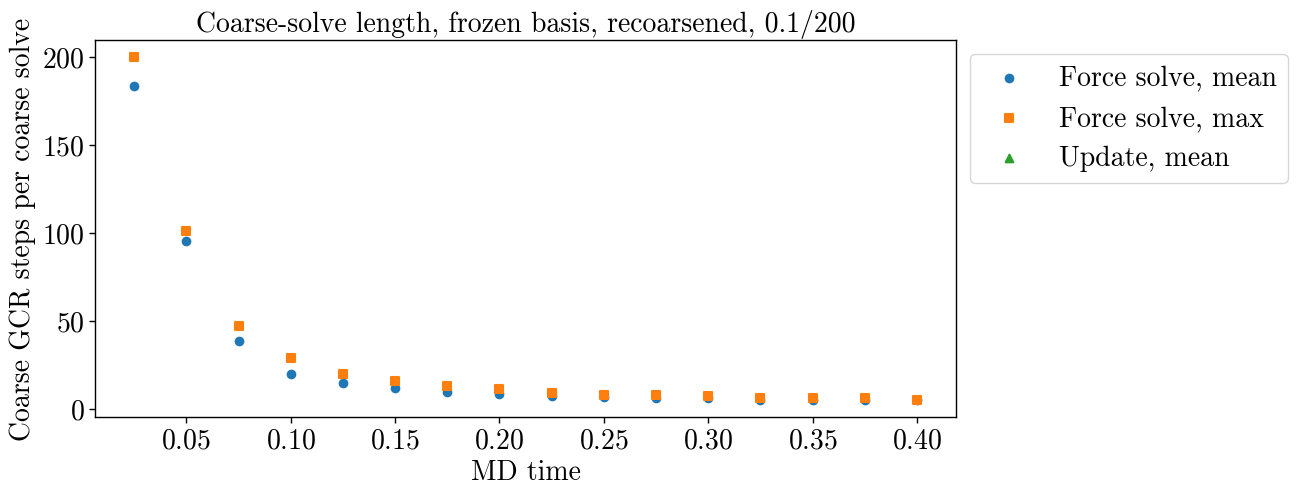

In [7]:
for i, (label, r) in enumerate(runs.items()):
    c = r["coarse"]
    display(c)

    f = c[c["kind"] == "step"].merge(r["steps"][["global", "md_time", "matvecs", "seconds", "t_coarse"]], on="global")
    f["rho"] = f["t_coarse"] / f["steps_total"] / t_fine
    f["equiv_matvecs"] = f["matvecs"] + f["rho"] * f["steps_total"]
    print(f"{label}: rho median {f['rho'].median():.2f}; force solve in fine-matvec equivalents, "
          f"mean {f['equiv_matvecs'].mean():.0f} against the baseline's {gcr['steps']['matvecs'].mean():.0f}")
    display(f[["global", "md_time", "solves", "capped", "steps_mean", "steps_total", "rho", "matvecs", "equiv_matvecs"]])

    fig, ax = pt.add_subplots()
    ax = ax[0]
    lab = [r"MD time", r"Coarse GCR steps per coarse solve"]
    pt.scatter_1d(f["md_time"], f["steps_mean"], ax=ax, col=pt.pal[0], mkr='o', fn_label="Force solve, mean", ax_label=lab)
    pt.scatter_1d(f["md_time"], f["steps_max"], ax=ax, col=pt.pal[1], mkr='s', fn_label="Force solve, max", ax_label=lab)
    u = c[c["kind"] == "update"].copy()
    u["md_time"] = u["global"] * r["dtau"]
    pt.scatter_1d(u["md_time"], u["steps_mean"], ax=ax, col=pt.pal[2], mkr='^', fn_label="Update, mean", ax_label=lab)
    pt.add_title(ax, f"Coarse-solve length, {label}")
    ax.legend(**LEGEND)
    plt.show()

## 7. The updates

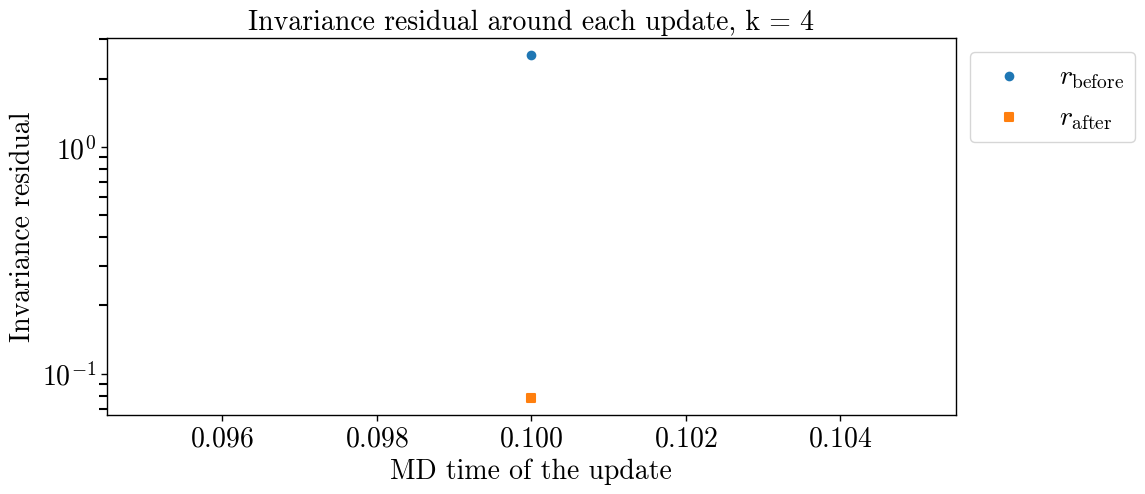

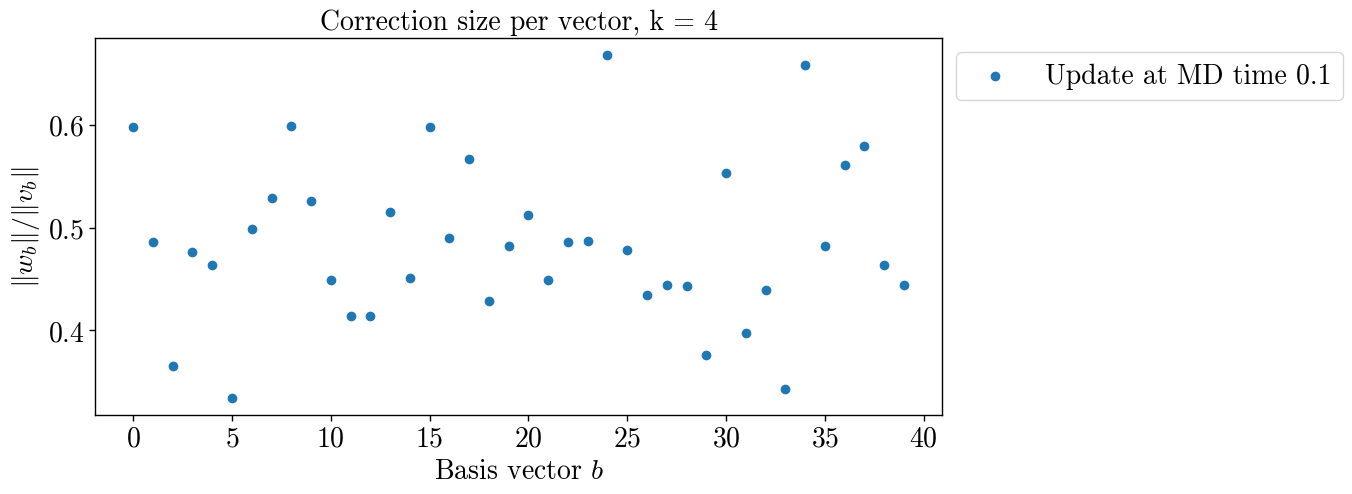

,traj,step,md_time,matvecs,seconds,in_force_solves,capped,resid_before,resid_after,cap_S0,dist2_prev,gram_cond,iters_mean,iters_max,wratio_mean
0,1,4,0.1,51440.0,39733.2604,47.951014,40.0,2.547347,0.077974,0.984459,8.851615,209.248692,64.0,64,0.484473


""


In [8]:
for label, r in runs.items():
    if len(r["updates"]) == 0:
        continue
    u = r["updates"].copy()
    u["iters_mean"] = u["iters"].apply(np.mean)
    u["iters_max"] = u["iters"].apply(np.max)
    u["wratio_mean"] = u["wratio"].apply(np.mean)
    u["in_force_solves"] = u["seconds"] / r["steps"]["seconds"].mean()

    fig, ax = pt.add_subplots()
    ax = ax[0]
    lab = [r"MD time of the update", r"Invariance residual"]
    pt.scatter_1d(u["md_time"], u["resid_before"], ax=ax, col=pt.pal[0], mkr='o', fn_label=r"$r_{\rm before}$", ax_label=lab, logy=True)
    pt.scatter_1d(u["md_time"], u["resid_after"], ax=ax, col=pt.pal[1], mkr='s', fn_label=r"$r_{\rm after}$", ax_label=lab, logy=True)
    pt.add_title(ax, f"Invariance residual around each update, {label}")
    ax.legend(**LEGEND)
    plt.show()

    fig, ax = pt.add_subplots()
    ax = ax[0]
    pt.scatter_1d(np.arange(len(u["wratio"].iloc[0])), u["wratio"].iloc[0], ax=ax, col=pt.pal[0], mkr='o',
                  fn_label=f"Update at MD time {u['md_time'].iloc[0]:g}",
                  ax_label=[r"Basis vector $b$", r"$\|w_b\| / \|v_b\|$"])
    pt.add_title(ax, f"Correction size per vector, {label}")
    ax.legend(**LEGEND)
    plt.show()

    display(u[["traj", "step", "md_time", "matvecs", "seconds", "in_force_solves", "capped", "resid_before", "resid_after",
               "cap_S0", "dist2_prev", "gram_cond", "iters_mean", "iters_max", "wratio_mean"]])
    display(r["fresh"])

## 8. Conclusions (preliminary: trajectory 1 only, one source per MD step)

1. **The MG works on a fresh basis.** At MD step 1 a force solve takes 33 outer steps and 650 fine matvecs, against a baseline of about 20000 matvecs that mostly does not converge.
2. **The coarse solve dominates its cost.** About 96% of each force solve is the coarse GCR: hundreds of steps per MG application, each priced at $\rho \approx 0.9$ fine matvecs, because the $N = 40$, 33-point coarse operator costs about as much to apply as $A$.
3. **A frozen basis with a frozen coarse operator fails outright.** In 425417 outer iterations go 33, 39, 49, 217, and from step 5 ($d_U \approx 0.02$) every solve hits the 1008-step cap at about 15000 s, stalling at $\mathrm{relres} \sim 10^{-3}$; almost every coarse solve hits its own cap.
4. **Recoarsening every step prevents the stall but not the loss of the MG advantage.** In 425622 every solve to step 8 reaches $\epsilon_F$ and steps 9–16 stop at the cap within a factor of 10 of it, at 250–580 s each. But outer iterations rise 42, 135, 247, 421 over steps 1–4, faster than without recoarsening, and from step 9 ($d_U \approx 0.064$) a force solve uses as many fine matvecs as plain GCR plus the coarse work.
5. **What recoarsening does to the coarse problem.** Coarse steps per MG application fall from about 400 at step 1 to about 9 at step 16: the Galerkin operator built from a stale basis becomes well conditioned. I think this is the mechanism: once the near-null vectors of $A(U)$ leave the span of the stale basis, $P^\dagger A(U) P$ loses the small eigenvalues the coarse correction exists to deflate, so the coarse solve becomes cheap and useless, and the outer GCR has to resolve the low modes itself.
6. **The looser coarse solve (425623) helps a little.** It takes 4–40% more outer steps over steps 1–8 but less wall time at every step, and the 16 steps take 7470 s against 8239 s (9% less).
7. **Consequence for the algorithm.** Neither variant keeps the MG advantage past $d_U \approx 0.01$, three to four MD steps at $\delta\tau = 0.025$. Without recoarsening the outer count stays within $1.5\times$ of the fresh-basis 33 through step 3 ($d_U = 0.007$) and then collapses; with recoarsening it is $4\times$ already at step 2 ($d_U = 0.003$). So the basis has to be refreshed every MD step or two. The perturbative update as implemented costs 7–11 h, against a budget of a few hundred seconds per step, so it has to become two to three orders of magnitude cheaper, or be replaced by something that tracks the lowest modes directly.